## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [2]:
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Jiaxian Wang

**Date:** 10/21/2026

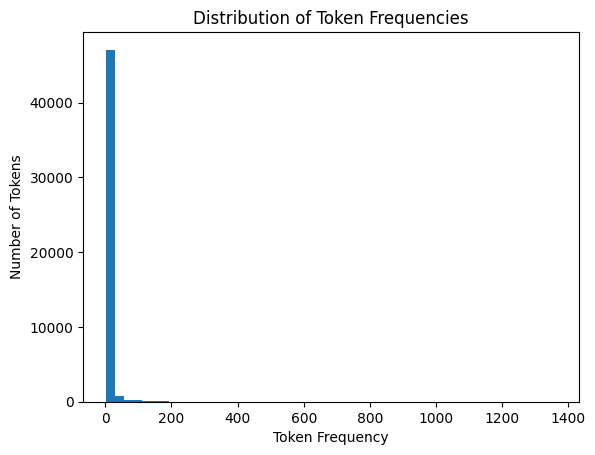

In [3]:
# Your Phase 1 solution to the problem goes here.
#Q1
import matplotlib.pyplot as plt
freq = [count for token, count in token_freq]
plt.hist(freq, bins=50)
plt.xlabel("Token Frequency")
plt.ylabel("Number of Tokens")
plt.title("Distribution of Token Frequencies")
plt.show()

The distribution is right-skewed. Most tokens appear only a few times. There is a very small number of tokens appear frequently. The histogram shows a tall bar on the left, with very few visible bars on the right.

In [6]:
#Q2
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
df = pd.read_parquet("Phishing_clean.parquet")
X = df.drop(columns=["Email Type"])
y = df["Email Type"]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
print("Train R²:", model.score(X_train, y_train))
print("Test R²:", model.score(X_test, y_test))
coef =pd.Series(model.coef_, index=X.columns)
print(coef.loc[coef.abs().sort_values().tail(10).index])

Train R²: 0.7670143724934355
Test R²: 0.6658718438847919
a:active             0.574480
gray;               -0.574480
form.                0.576886
aging                0.594956
helvetica,           0.598560
background-image:   -0.622909
crawler              0.696167
thermal              0.747006
localized            0.824350
intervention        -1.259257
dtype: float64


 The training R squared is 0.76, and the test R squared is 0.67. The model performs better on the training set. The tokens with the largest absolute coefficients are intervention, localized and thermal. Intervention has the largest absolute coefficient.

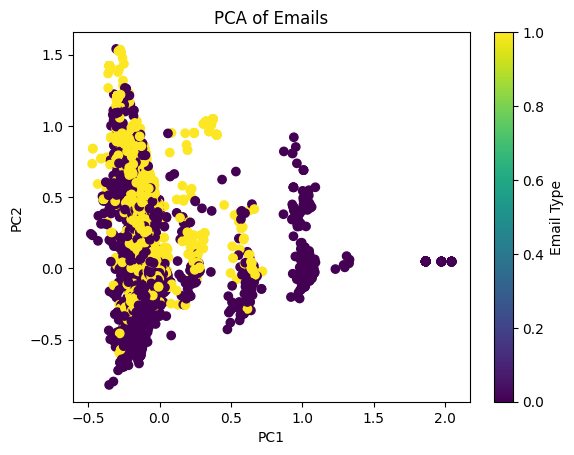

In [7]:
#Q3
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
plt.scatter(X_pca[:,0], X_pca[:,1], c=y)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Emails")
plt.colorbar(label="Email Type")
plt.show()

First two principal components seems not separating two groups clearly. They overlap a lot, especially on the left part. Non-scam emails are more common when PC1 is higher, and scam emails are more concentrated on the left and middle.

In [8]:
#Q4
pca = PCA(n_components=2610)
X_train_pca = pca.fit_transform(X_train)
X_test_pca =pca.transform(X_test)
model_pca = LinearRegression()
model_pca.fit(X_train_pca, y_train)
print("Train R²:", model_pca.score(X_train_pca, y_train))
print("Test R²:", model_pca.score(X_test_pca, y_test))

Train R²: 0.7662326827745849
Test R²: 0.6683390643101164


The training R squared is 0.77, and the test R squared is 0.67. Both values are slightly higher than the original linear regression in Q2. PCA did not make big differences because the improvement is somehow little in model performance

Q5: The advantage of using PCA is that PCA could help reduce the number of features while keeping most of the important information. It also remove correlations in features to make the regression simpler and more stable.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 07c418c
- **AI tool and model used:** ChatGPT

### *Prompts used

1. Review my Phase 1 solutions for Question 1-5. Identify weaknesses and help me improve.

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Q1: Use a log scale or adjust the x-axis range to make the histogram easier to read.
2. Q2: Explain what positive and negative regression coefficients mean instead of only listing the most important tokens.
3. Q2: Add a short explanation comparing training and test R² to discuss how well the model performs on new data.
4. Q3: Add a legend and use different colors for the two email types in the PCA scatter plot.
5. Q4: Correct the R² comparison. PCA slightly decreased training R² but slightly increased test R².
6. Q5: Explain when PCA is useful and connect its advantages to the results from Q4.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept| Changing the scale can make the histogram easier to read. |
| 2 | Accept| Explain in detail could make the regression results easier to understand. |
| 3 | Accept| Discuss this difference helps better explain model performance. |
| 4 | Accept| Different colors and a legend could make the two email types easier to compare. |
| 5 | Accept| Adjust mistakes |
| 6 | modify| Add explanation of when PCA is useful |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

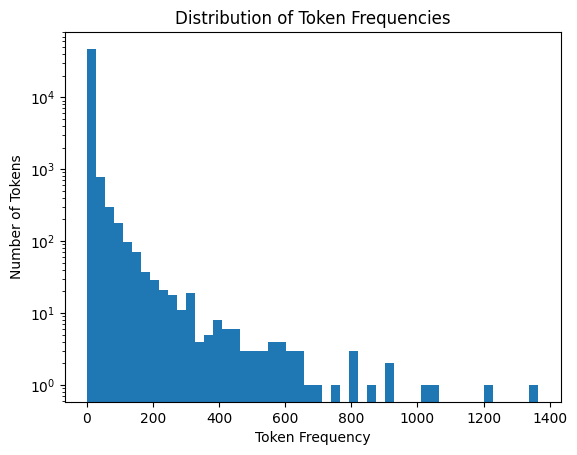

In [9]:
# Your Phase 2 solution to the problem goes here.
#Q1
import matplotlib.pyplot as plt
freq = [count for token, count in token_freq]
plt.hist(freq, bins=50)
plt.yscale("log")
plt.xlabel("Token Frequency")
plt.ylabel("Number of Tokens")
plt.title("Distribution of Token Frequencies")
plt.show()

The distribution is right-skewed. Most tokens appear only a few times. There is a very small number of tokens appear frequently. The histogram shows a tall bar on the left, with very few visible bars on the right.

In [10]:
#Q2
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
df = pd.read_parquet("Phishing_clean.parquet")
X = df.drop(columns=["Email Type"])
y = df["Email Type"]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
print("Train R²:", model.score(X_train, y_train))
print("Test R²:", model.score(X_test, y_test))
coef =pd.Series(model.coef_, index=X.columns)
print(coef.loc[coef.abs().sort_values().tail(10).index])

Train R²: 0.7670143724934355
Test R²: 0.6658718438847919
a:active             0.574480
gray;               -0.574480
form.                0.576886
aging                0.594956
helvetica,           0.598560
background-image:   -0.622909
crawler              0.696167
thermal              0.747006
localized            0.824350
intervention        -1.259257
dtype: float64


The training R squared is 0.77, and the test R squared is 0.67. The model performs better on the training set than the test set, which suggests it does not perform as well on new data. The tokens with the largest absolute coefficients are intervention, localized, and thermal. Positive coefficients increase the predicted value, while negative coefficients decrease it. Intervention has the largest absolute coefficient.

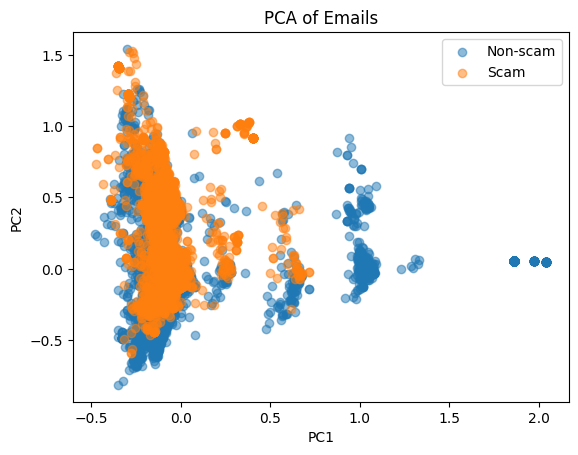

In [11]:
#Q3
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
plt.scatter(X_pca[y==0, 0], X_pca[y==0, 1], label="Non-scam", alpha=0.5)
plt.scatter(X_pca[y==1, 0], X_pca[y==1, 1], label="Scam", alpha=0.5)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Emails")
plt.legend()
plt.show()

First two principal components seems not separating two groups clearly. They overlap a lot, especially on the left part. Non-scam emails are more common when PC1 is higher, and scam emails are more concentrated on the left and middle.

In [12]:
#Q4
pca = PCA(n_components=2610)
X_train_pca = pca.fit_transform(X_train)
X_test_pca =pca.transform(X_test)
model_pca = LinearRegression()
model_pca.fit(X_train_pca, y_train)
print("Train R²:", model_pca.score(X_train_pca, y_train))
print("Test R²:", model_pca.score(X_test_pca, y_test))

Train R²: 0.7662326827745849
Test R²: 0.6683390643101164


The training R squared is 0.77, and the test R squared is 0.67. Compared to Q2, the training R squared is slightly lower, while the test R squared is slightly higher. PCA did not make a big difference in model performance.

Q5: The advantage of using PCA is that it can reduce the number of features while keeping most of the important information. It also removes correlations between features, which can make regression simpler and more stable. PCA is especially useful when there are many features that are highly correlated. However, in Q4, PCA did not make a big difference in model performance.

### *Reflection on AI assistance
In your own words without generative AI.

In this assignment, AI is much more useful than previous ones. In addition to explnations, I used AI suggestions to improve my code and visualizations. For Q1, AI asked me to add a log scale to make the histogram easier to read, as the distribution was strongly right-skewed. In Q2, I added more explanation on what positive and negative regression coefficients mean. For Q3, AI suggested me to  use different colors and added a legend in the scatterplot to make two email types easier to compare. The biggest surprise AI gave to me was on Q4. It pointed out a small mistake, which I am totally not aware of. There are some limitations of AI still. It still work under the existing models or code structures, making improvements or small adjustments. However, its performance was better than I expected. Overall, AI was much more helpful this time as it really find my mistakes. I verified all codes and explanations from AI, so I don't have remaining concerns about the final solution. I will be more careful next time to avoid mistakes!